# Data check

Quick check of `evonn.data`. We want to be sure the generator works before we run experiments.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from evonn.data import (
    f, generate_datasets,
    SIGMA, NOISE_FLOOR, TRAIN_SIZES, X_LOW, X_HIGH,
)

## 1. Target surface
This is what the model has to learn. It is made of two sine waves, so it looks like a wavy surface with hills and valleys. There is one peak (+2) at (0.5, 0.5), one valley (-2) at (-0.5, -0.5) and two saddle points.

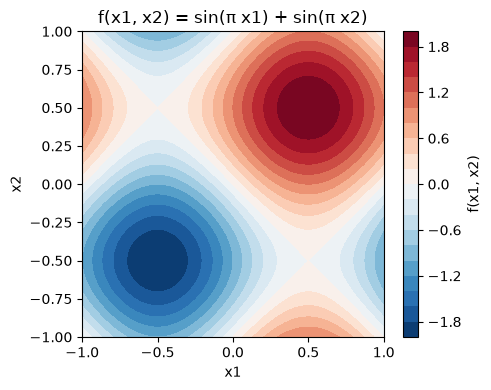

In [2]:
grid = np.linspace(X_LOW, X_HIGH, 200)
x1, x2 = np.meshgrid(grid, grid)
X_grid = np.column_stack([x1.ravel(), x2.ravel()])
z = f(X_grid).reshape(x1.shape)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.contourf(x1, x2, z, levels=20, cmap="RdBu_r")
fig.colorbar(im, ax=ax, label="f(x1, x2)")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("f(x1, x2) = sin(π x1) + sin(π x2)")
plt.tight_layout()
plt.show()

## 2. Clean vs noisy targets
The model only sees the noisy data. The first figure shows f(X) on the left and y on the right. The second figure is easier to read: the line is f(x1, 0) and the dots are training points with |x2| < 0.05. We use a small band, not x2 = 0 exactly, to have enough points, so the dots are a bit off the line. The histogram checks that the noise is close to N(0, 0.09).

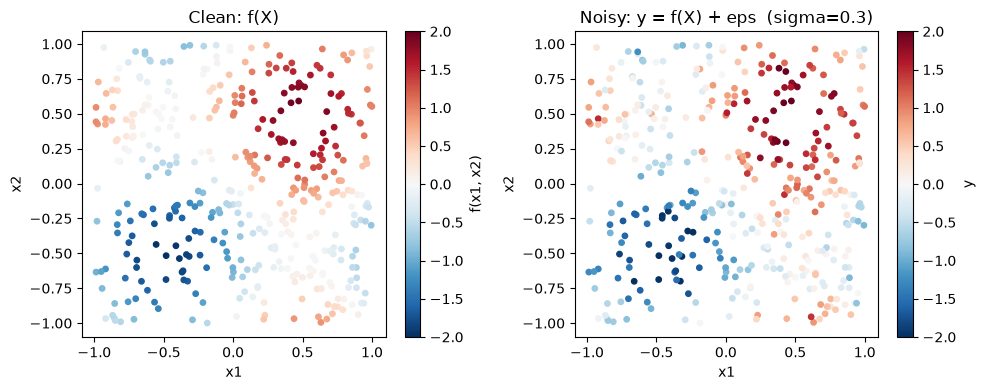

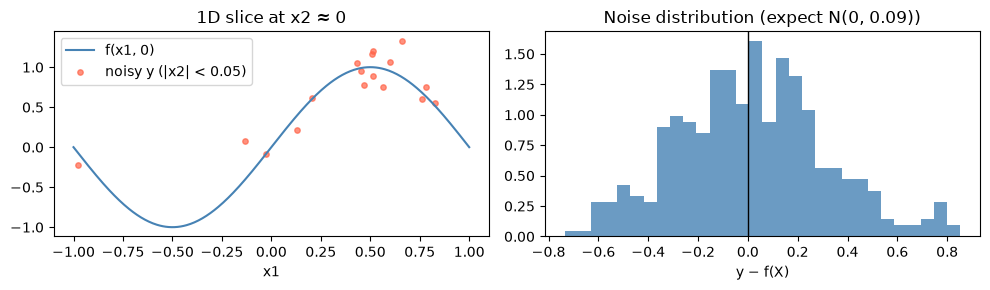

residual mean: 0.0147  (expect ~0, margin ±0.030 for n=400)
residual std:  0.3004  (expect ~0.3)


In [3]:
d = generate_datasets(seed=0)
X_tr, y_tr = d["train"][400]
residual = y_tr - f(X_tr)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sc = axes[0].scatter(X_tr[:, 0], X_tr[:, 1], c=f(X_tr), cmap="RdBu_r", vmin=-2, vmax=2, s=15)
fig.colorbar(sc, ax=axes[0], label="f(x1, x2)")
axes[0].set_title("Clean: f(X)")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")

sc2 = axes[1].scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="RdBu_r", vmin=-2, vmax=2, s=15)
fig.colorbar(sc2, ax=axes[1], label="y")
axes[1].set_title(f"Noisy: y = f(X) + eps  (sigma={SIGMA})")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")

plt.tight_layout()
plt.show()

# 1D slice: fix x2=0 so only the x1 wave is visible
x1_line = np.linspace(X_LOW, X_HIGH, 400)
curve = f(np.column_stack([x1_line, np.zeros_like(x1_line)]))
near = np.abs(X_tr[:, 1]) < 0.05

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(x1_line, curve, label="f(x1, 0)", color="steelblue")
axes[0].scatter(X_tr[near, 0], y_tr[near], s=15, alpha=0.7, color="tomato", label="noisy y (|x2| < 0.05)")
axes[0].legend()
axes[0].set_xlabel("x1")
axes[0].set_title("1D slice at x2 ≈ 0")

axes[1].hist(residual, bins=30, density=True, color="steelblue", alpha=0.8)
axes[1].axvline(0, color="k", linewidth=1)
axes[1].set_xlabel("y − f(X)")
axes[1].set_title("Noise distribution (expect N(0, 0.09))")

plt.tight_layout()
plt.show()

n = len(X_tr)
print(f"residual mean: {residual.mean():.4f}  (expect ~0, margin ±{2*SIGMA/n**0.5:.3f} for n={n})")
print(f"residual std:  {residual.std():.4f}  (expect ~{SIGMA})")

## 3. Noise floor

We compare the noisy test values y with the clean f(X). We use the 5000 test points. The MSE should be close to sigma^2 = 0.09. No model can do better than this error, so we use it as a reference line in all plots.

In [4]:
X_test, y_test = d["test"]
empirical_floor = np.mean((y_test - f(X_test)) ** 2)

n_test = len(X_test)
margin = 2 * np.sqrt(2 / n_test) * SIGMA**2
print(f"theoretical noise floor: {NOISE_FLOOR:.4f}")
print(f"empirical  noise floor:  {empirical_floor:.4f}  (margin ±{margin:.4f} for n={n_test})")

theoretical noise floor: 0.0900
empirical  noise floor:  0.0894  (margin ±0.0036 for n=5000)


## 4. Nested training sets

All training sets come from the same pool (seed 0). n=25 is the first 25 points, n=100 is the first 100, and so on. Each colour shows the size where the point is added: red (n=25), orange (26 to 100), green (101 to 400), blue (401 to 1600). The last panel should show all four colours.

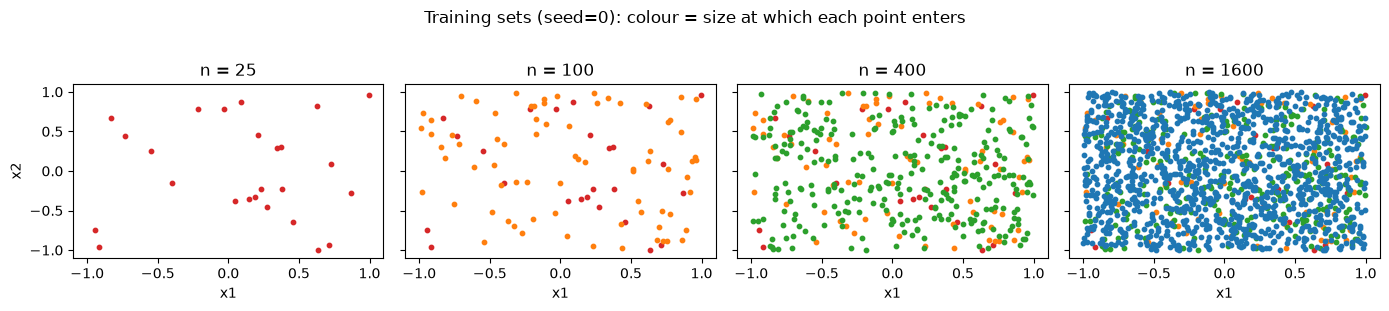

nested: OK


In [5]:
sizes = sorted(TRAIN_SIZES)
colors = ["tab:red", "tab:orange", "tab:green", "tab:blue"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True, sharey=True)
for ax, n in zip(axes, sizes):
    X_n, _ = d["train"][n]
    start = 0
    for s, c in zip(sizes, colors):
        if s > n:
            break
        ax.scatter(X_n[start:s, 0], X_n[start:s, 1], s=10, color=c)
        start = s
    ax.set_title(f"n = {n}")
    ax.set_xlabel("x1")

axes[0].set_ylabel("x2")
fig.suptitle("Training sets (seed=0): colour = size at which each point enters", y=1.02)
plt.tight_layout()
plt.show()

for small, big in zip(sizes[:-1], sizes[1:]):
    assert np.array_equal(d["train"][small][0], d["train"][big][0][:small])
    assert np.array_equal(d["train"][small][1], d["train"][big][1][:small])
print("nested: OK")

## 5. Figure for the report

This is the figure we use in the report. Left: the true function f. Right: the noisy values y against the true values f(x). The line is y = f(x) and the shaded band is ±2σ. The spread around the line is the noise.

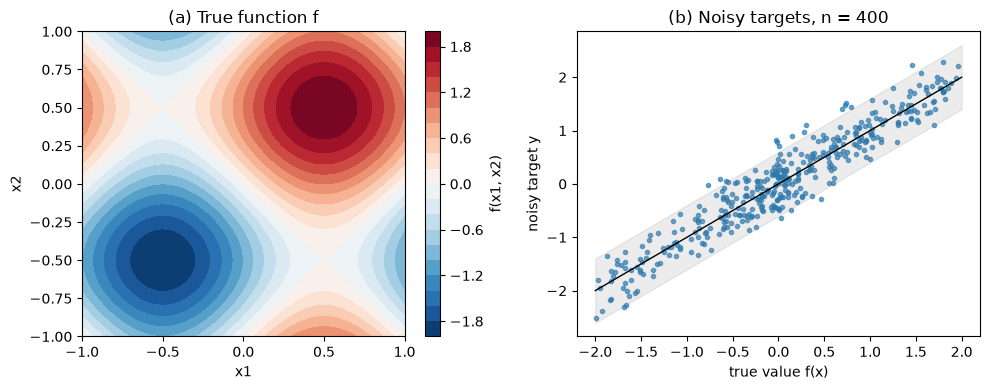

In [6]:
import os

fx = f(X_tr)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im = axes[0].contourf(x1, x2, z, levels=20, cmap="RdBu_r")
fig.colorbar(im, ax=axes[0], label="f(x1, x2)")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].set_title("(a) True function f")

axes[1].scatter(fx, y_tr, s=9, alpha=0.65)
axes[1].plot([-2, 2], [-2, 2], color="k", linewidth=1)
axes[1].fill_between([-2, 2], [-2 - 2*SIGMA, 2 - 2*SIGMA], [-2 + 2*SIGMA, 2 + 2*SIGMA], color="grey", alpha=0.15)
axes[1].set_xlabel("true value f(x)")
axes[1].set_ylabel("noisy target y")
axes[1].set_title(f"(b) Noisy targets, n = {len(X_tr)}")

plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
fig.savefig("../figures/data_surface.png", dpi=200, bbox_inches="tight")
plt.show()